In [1]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import config
import general
import contraction
import constantes
import profiles

import pandas as pd

from scipy.integrate import quad

In [2]:
plt.rcParams['axes.labelsize'] = 20  
plt.rcParams['xtick.labelsize'] = 18   
plt.rcParams['ytick.labelsize'] = 18

XLIM = (20, 210)
YLIM = (1e-6, 1e-1)
FIGSIZE = (10,10)

In [ ]:
import importlib
import config, constantes, general, profiles, contraction
# Force reload all modules to clear any bad cached states
importlib.reload(config)
importlib.reload(constantes)
importlib.reload(profiles)
importlib.reload(contraction)
importlib.reload(general)

# 1. Force exact observational parameters directly into memory
config.HALO_MASS = 1.8e15 * 0.7
config.CONCENTRATION = 3.1
config.ALPHA_CUSTOM = 1.0
config.BETA_CUSTOM = 3.0
config.GAMMA_CUSTOM = 1.09
constantes.Z = 0.28

# Force the critical density and virial overdensity exactly to Abell 1703's epoch
from astropy.cosmology import Planck18 as cosmo
constantes.RHO_C = cosmo.critical_density(constantes.Z).to("M_sun / Mpc3").value / constantes.H**2
constantes.DELTA_VIR = 200 

# 2. Reset the grid explicitly to prevent recursive shrinking on re-runs
config.R = np.logspace(np.log10(0.02), np.log10(0.21), 500) * constantes.H

# Run the simulation
halo = general.contract_halo()

# 3. Convert the simulated radius from Mpc/h back to physical kpc
r_kpc_sim = (halo['r'] / constantes.H) * 1000.0
rf_kpc_sim = (halo['r_f'] / constantes.H) * 1000.0

dm = halo['dm_profile']
bar = halo['baryon_profile']
cnt = halo['contraction']
rho_baryons = halo['rho_stars'] + halo['rho_gas']

# Calculate Abell 1703 Observational Truth [20 - 210 kpc]
r_s_kpc = 727.0
alpha = 1.09
c200 = 3.1
r_cut_cd_kpc = 30.0 
sigma_0_cd = 299.4
G_kpc = 4.30091e-6

r_kpc_obs = np.linspace(20, 210, 500)

# Normalizations
rho_0_dpie_kpc = (sigma_0_cd**2) / (2 * np.pi * G_kpc)

def gnfw_integrand(x, alpha_val):
    return (x**2) / ((x**alpha_val) * (1 + x)**(3 - alpha_val))

integral_val, _ = quad(gnfw_integrand, 0, c200, args=(alpha,))

z_cluster = 0.28
H0 = 70.0
Omega_m = 0.3
Omega_L = 0.7

Hz_kpc = (H0 / 1000.0) * np.sqrt(Omega_m * (1 + z_cluster)**3 + Omega_L)
rho_crit_z = (3 * Hz_kpc**2) / (8 * np.pi * G_kpc)
rho_s_kpc = (200.0 / 3.0) * rho_crit_z * (c200**3) / integral_val

density_cd_pc = (rho_0_dpie_kpc / ((r_kpc_obs**2) * (1 + (r_kpc_obs / r_cut_cd_kpc)**2))) / 1e9
x = r_kpc_obs / r_s_kpc
density_gnfw_pc = (rho_s_kpc / ((x**alpha) * (1 + x)**(3 - alpha))) / 1e9

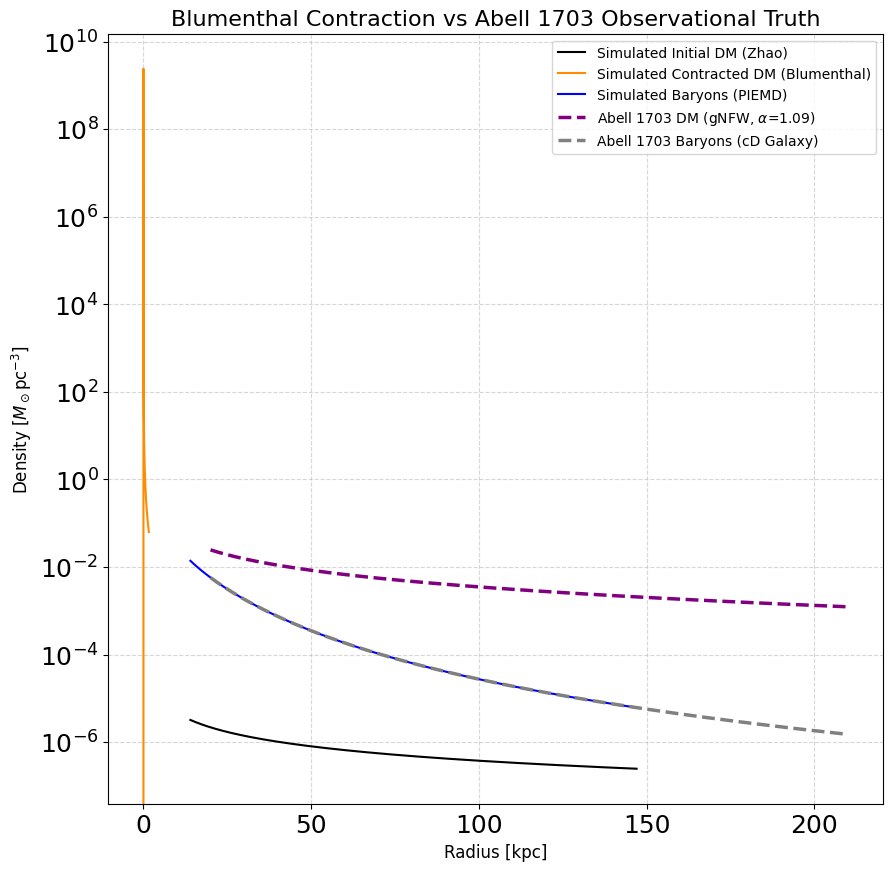

In [4]:
FIGSIZE = (10,10)
plt.figure(figsize=FIGSIZE)

# Plot Simulated Profiles (mapping simulated arrays to kpc)
plt.semilogy(r_kpc_sim, halo['rho_dm_initial'] , label=f'Simulated Initial DM ({dm})', color='black')
plt.semilogy(rf_kpc_sim, halo['rho_dm_contracted'] , label=f'Simulated Contracted DM ({cnt})', color='darkorange')
plt.semilogy(r_kpc_sim, rho_baryons , label=f'Simulated Baryons ({bar})', color='blue')

# Plot Observational Truth (Abell 1703) on absolute kpc scale
plt.semilogy(r_kpc_obs, density_gnfw_pc, label=f'Abell 1703 DM (gNFW, $\\alpha$={alpha})', color='purple', ls='--', linewidth=2.5)
plt.semilogy(r_kpc_obs, density_cd_pc, label=f'Abell 1703 Baryons (cD Galaxy)', color='grey', ls='--', linewidth=2.5)

# plt.xlim(XLIM)
# plt.ylim(YLIM)

plt.title(f"{cnt.capitalize()} Contraction vs Abell 1703 Observational Truth", fontsize=16)
plt.xlabel(r'Radius [kpc]', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()